In [5]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")
import scipy.stats
import math
from statsmodels.formula.api import ols
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_white

In [6]:
ibm = pd.read_csv("IBM_5y_1d.csv", parse_dates=["date"])
wmt = pd.read_csv("WMT_5y_1d.csv", parse_dates=["date"])

print("IBM:", ibm.shape)
print("WMT:", wmt.shape)
print(ibm.head())

IBM: (1254, 7)
WMT: (1254, 7)
        date        open        high         low       close    adjClose  \
0 2021-10-11  137.189301  137.743790  136.137665  136.166351  112.455612   
1 2021-10-12  135.956024  136.042068  134.130020  134.292542  110.908089   
2 2021-10-13  134.340347  135.191208  133.518158  134.569794  111.137077   
3 2021-10-14  134.837479  137.590820  134.808792  137.084137  113.213577   
4 2021-10-15  137.084137  138.479919  136.510513  138.250473  114.176842   

    volume  
0  2921792  
1  3293436  
2  3013003  
3  4410668  
4  3371049  


In [7]:
# Retornos diarios
ret_ibm = ibm["adjClose"].pct_change().dropna().reset_index(drop=True)
ret_wmt = wmt["adjClose"].pct_change().dropna().reset_index(drop=True)

n_muestra = 5
Y = ret_wmt.iloc[:n_muestra].values.reshape(-1, 1)
X1 = ret_ibm.iloc[:n_muestra].values

# Matriz de diseño X = [1, X1]
X = np.column_stack([np.ones(n_muestra), X1])

print("Y (retornos WMT):")
print(Y)
print("\nX (matriz de diseño):")
print(X)

Y (retornos WMT):
[[-0.00107508]
 [-0.00724633]
 [ 0.01084063]
 [ 0.00486158]
 [ 0.00803997]]

X (matriz de diseño):
[[ 1.         -0.01376119]
 [ 1.          0.00206467]
 [ 1.          0.01868413]
 [ 1.          0.00850838]
 [ 1.         -0.01583567]]


In [8]:
XT_X = np.matmul(np.matrix.transpose(X), X)
print("XᵀX:")
print(XT_X)

XᵀX:
[[ 5.00000000e+00 -3.39682362e-04]
 [-3.39682362e-04  8.65891325e-04]]


In [9]:
XT_X_inv = np.linalg.inv(XT_X)
print("(XᵀX)⁻¹:")
print(XT_X_inv)

(XᵀX)⁻¹:
[[2.00005330e-01 7.84605193e-02]
 [7.84605193e-02 1.15491012e+03]]


In [10]:
XT_Y = np.matmul(np.matrix.transpose(X), Y)
print("XᵀY:")
print(XT_Y)

XᵀY:
[[0.01542077]
 [0.00011643]]


In [11]:
betas = np.matmul(XT_X_inv, XT_Y)
print("Betas:")
print(betas)
print(f"\nβ0 (intercepto) = {betas[0,0]:.6f}")
print(f"β1 (pendiente)   = {betas[1,0]:.6f}")

Betas:
[[0.00309337]
 [0.13567226]]

β0 (intercepto) = 0.003093
β1 (pendiente)   = 0.135672


In [12]:
Y_pred = np.matmul(X, betas)
print("Pronósticos Ŷ:")
print(Y_pred)

Pronósticos Ŷ:
[[0.00122636]
 [0.00337349]
 [0.00562829]
 [0.00424772]
 [0.00094491]]


In [13]:
Resid = Y - Y_pred
print("Residuales:")
print(Resid)

Residuales:
[[-0.00230143]
 [-0.01061982]
 [ 0.00521234]
 [ 0.00061386]
 [ 0.00709506]]


In [14]:
RSS = np.matmul(np.matrix.transpose(Resid), Resid)
print("RSS:")
print(RSS)

RSS:
[[0.00019596]]


In [15]:
TSS = np.matmul(np.matrix.transpose(Y), Y) - len(Y) * (Y.mean() ** 2)
print("TSS:")
print(TSS)

TSS:
[[0.0002119]]


In [16]:
R_cuad = float(1 - RSS / TSS)
print("R²:")
print(R_cuad)

R²:
0.07521461931296569


In [17]:
s_cuad = RSS / (len(Y) - X.shape[1])
print("Varianza del error s²:")
print(s_cuad)

Varianza del error s²:
[[6.53207824e-05]]


In [18]:
s = math.sqrt(s_cuad)
print("Desviación estándar s:")
print(s)

Desviación estándar s:
0.008082127344092423


In [19]:
grados_libertad = len(Y) - X.shape[1]
Confianza = 0.95
q = (1 - Confianza) / 2
t_critico = abs(scipy.stats.t.ppf(q, df=grados_libertad))
print("t crítico:")
print(t_critico)

t crítico:
3.182446305284263


In [20]:
f = np.array([[1], [0.01]])

Margen_error = t_critico * (s * (float(np.matmul(np.matmul(np.matrix.transpose(f), XT_X_inv), f)) ** 0.5))
Pron_puntual = float(np.matmul(np.matrix.transpose(f), betas))
Lim_inferior = Pron_puntual - Margen_error
Lim_superior = Pron_puntual + Margen_error

print(f"Pronóstico puntual: {Pron_puntual:.6f}")
print(f"Margen de error:    {Margen_error:.6f}")
print(f"Intervalo de confianza: [{Lim_inferior:.6f}, {Lim_superior:.6f}]")

Pronóstico puntual: 0.004450
Margen de error:    0.014483
Intervalo de confianza: [-0.010033, 0.018933]


In [21]:
#Prueba de Jarque-Bera

skew = float(scipy.stats.skew(Resid, bias=True))
kurtosis = float(scipy.stats.kurtosis(Resid, fisher=False))
Jarque_Bera = (len(Y) / 6) * (skew ** 2 + ((kurtosis - 3) ** 2) / 4)

print(f"Asimetría:   {skew:.4f}")
print(f"Curtosis:    {kurtosis:.4f}")
print(f"Jarque-Bera: {Jarque_Bera:.4f}")
print(f"Valor crítico χ²(2, 0.95): {scipy.stats.chi2.ppf(0.95, df=2):.4f}")

if Jarque_Bera < scipy.stats.chi2.ppf(0.95, df=2):
    print("NO se rechaza H0")
else:
    print("Se rechaza H0")

Asimetría:   -0.5795
Curtosis:    2.0859
Jarque-Bera: 0.4539
Valor crítico χ²(2, 0.95): 5.9915
NO se rechaza H0


In [22]:
#Durbin Wtson
df_reg = pd.DataFrame({"Y": Y.flatten(), "X1": X1})
model = ols("Y ~ X1", data=df_reg).fit()

dw = durbin_watson(model.resid)
print(f"Durbin-Watson: {dw:.4f}")
print("→ Cercano a 2 = sin autocorrelación")
print("→ < 2 = autocorrelación positiva")
print("→ > 2 = autocorrelación negativa")

Durbin-Watson: 1.9545
→ Cercano a 2 = sin autocorrelación
→ < 2 = autocorrelación positiva
→ > 2 = autocorrelación negativa


In [23]:
#Prueba de White
white_test = het_white(model.resid, model.model.exog)
print(f"Estadístico de prueba: {white_test[0]:.4f}")
print(f"Valor p:               {white_test[1]:.4f}")
print(f"Valor crítico χ²(2, 0.95): {scipy.stats.chi2.ppf(0.95, df=2):.4f}")

if white_test[1] > 0.05:
    print("NO se rechaza H0: hay homocedasticidad")
else:
    print("Se rechaza H0: hay heterocedasticidad")

Estadístico de prueba: 0.8411
Valor p:               0.6567
Valor crítico χ²(2, 0.95): 5.9915
NO se rechaza H0: hay homocedasticidad


In [24]:
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

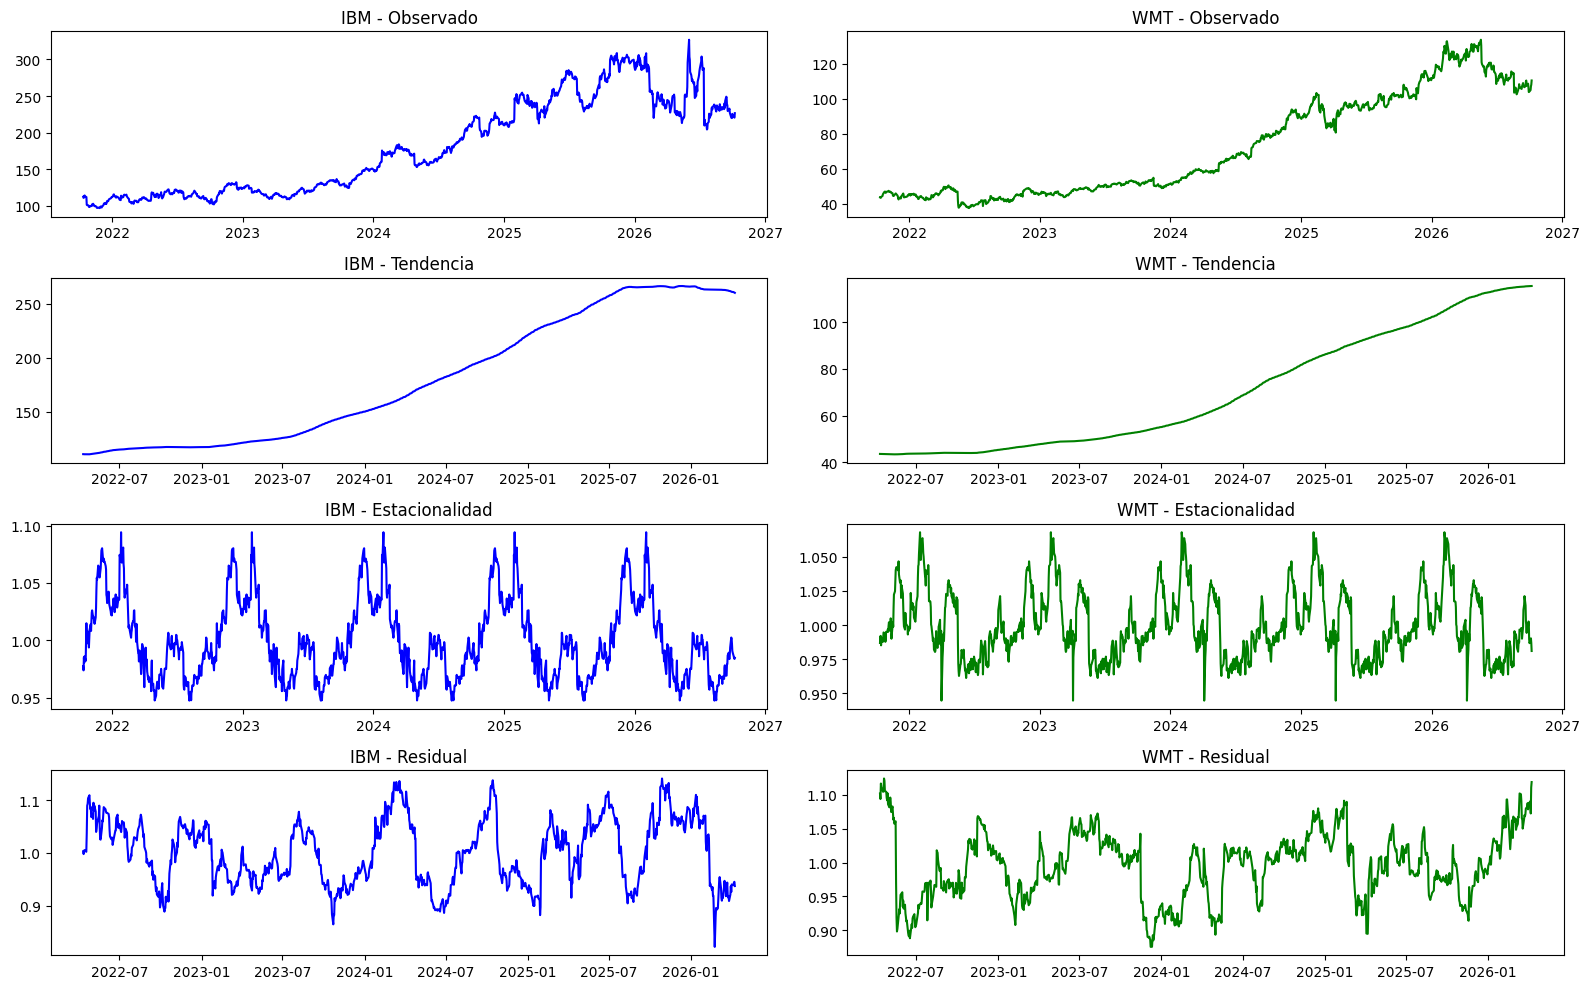

In [25]:
ibm_serie = ibm.set_index("date")["adjClose"]
wmt_serie = wmt.set_index("date")["adjClose"]

# Descomposición multiplicativa con período ~252 (días hábiles por año)
desc_ibm = seasonal_decompose(ibm_serie, model="multiplicative", period=252)
desc_wmt = seasonal_decompose(wmt_serie, model="multiplicative", period=252)

fig, axes = plt.subplots(4, 2, figsize=(16, 10))

# IBM
axes[0,0].plot(desc_ibm.observed, color="blue"); axes[0,0].set_title("IBM - Observado")
axes[1,0].plot(desc_ibm.trend, color="blue");    axes[1,0].set_title("IBM - Tendencia")
axes[2,0].plot(desc_ibm.seasonal, color="blue"); axes[2,0].set_title("IBM - Estacionalidad")
axes[3,0].plot(desc_ibm.resid, color="blue");    axes[3,0].set_title("IBM - Residual")

# WMT
axes[0,1].plot(desc_wmt.observed, color="green"); axes[0,1].set_title("WMT - Observado")
axes[1,1].plot(desc_wmt.trend, color="green");    axes[1,1].set_title("WMT - Tendencia")
axes[2,1].plot(desc_wmt.seasonal, color="green"); axes[2,1].set_title("WMT - Estacionalidad")
axes[3,1].plot(desc_wmt.resid, color="green");    axes[3,1].set_title("WMT - Residual")

plt.tight_layout()
plt.show()

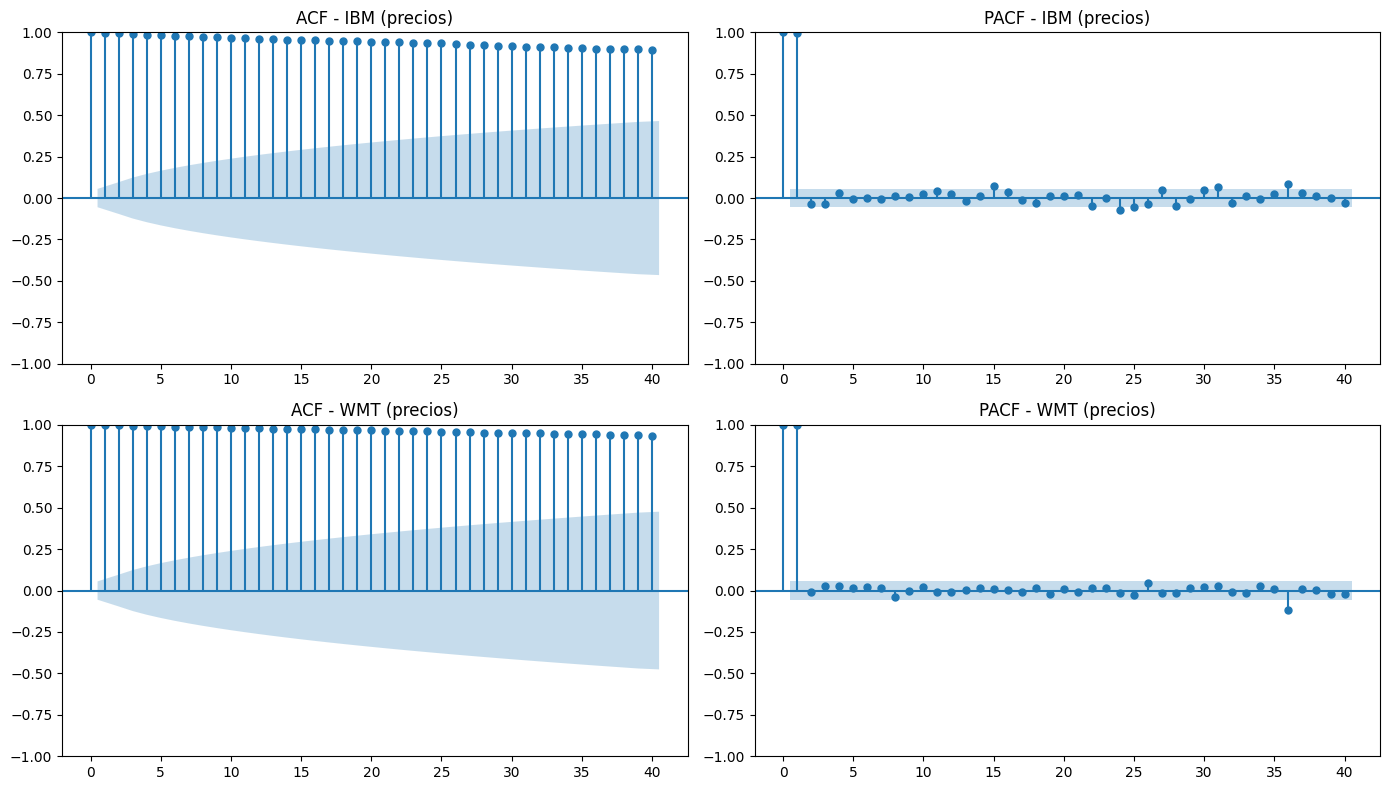

In [28]:
#Correlogramas de precios

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plot_acf(ibm_serie, lags=40, ax=axes[0,0]); axes[0,0].set_title("ACF - IBM (precios)")
plot_pacf(ibm_serie, lags=40, ax=axes[0,1]); axes[0,1].set_title("PACF - IBM (precios)")
plot_acf(wmt_serie, lags=40, ax=axes[1,0]); axes[1,0].set_title("ACF - WMT (precios)")
plot_pacf(wmt_serie, lags=40, ax=axes[1,1]); axes[1,1].set_title("PACF - WMT (precios)")
plt.tight_layout()
plt.show()

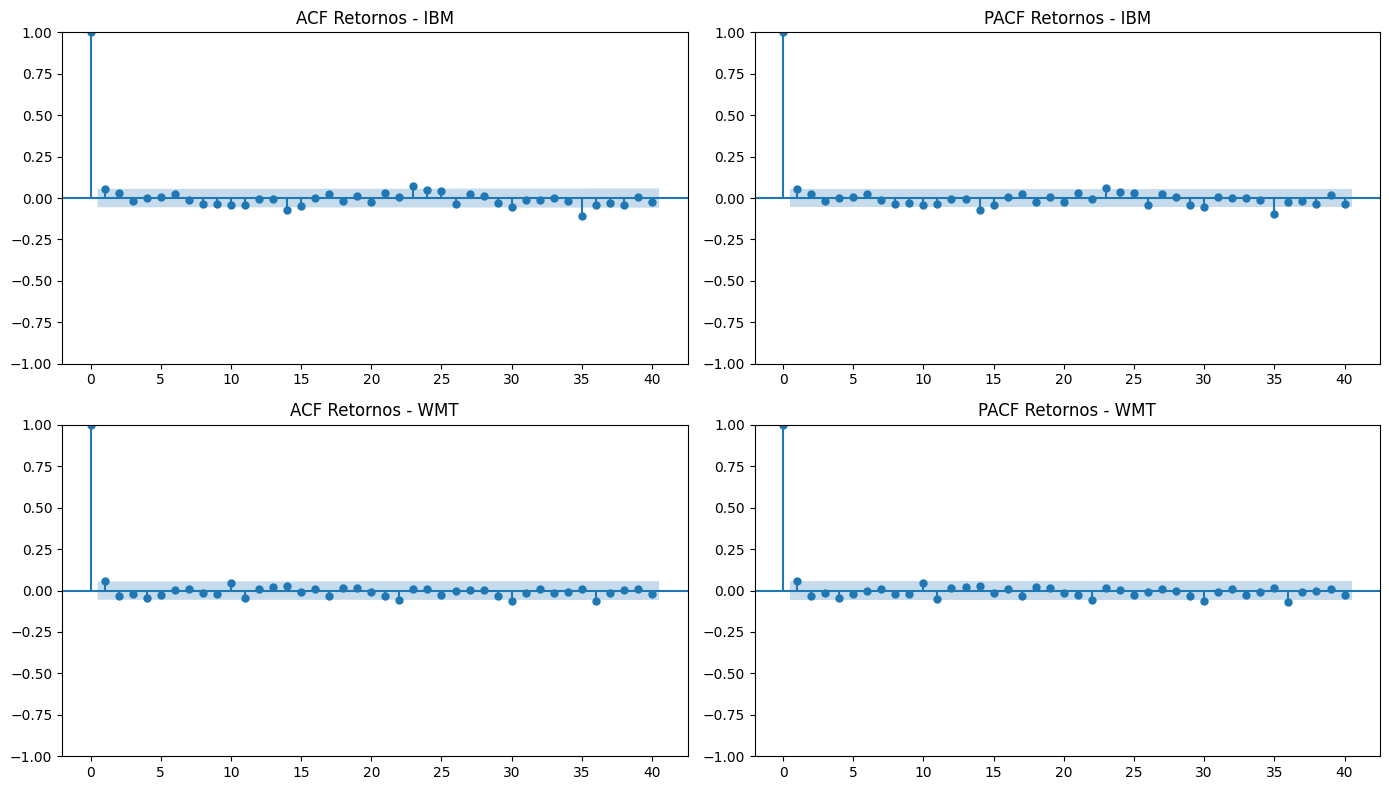

In [29]:
#Correlogramas de retornos


ret_ibm_full = ibm_serie.pct_change().dropna()
ret_wmt_full = wmt_serie.pct_change().dropna()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plot_acf(ret_ibm_full, lags=40, ax=axes[0,0]); axes[0,0].set_title("ACF Retornos - IBM")
plot_pacf(ret_ibm_full, lags=40, ax=axes[0,1]); axes[0,1].set_title("PACF Retornos - IBM")
plot_acf(ret_wmt_full, lags=40, ax=axes[1,0]); axes[1,0].set_title("ACF Retornos - WMT")
plot_pacf(ret_wmt_full, lags=40, ax=axes[1,1]); axes[1,1].set_title("PACF Retornos - WMT")
plt.tight_layout()
plt.show()

#### Prueba de Dickey-Fuller Aumentada

In [30]:
from statsmodels.tsa.stattools import adfuller

def prueba_adf(serie, nombre):
    resultado = adfuller(serie.dropna(), autolag="AIC")
    print(f"\n--- Prueba ADF: {nombre} ---")
    print(f"Estadístico ADF: {resultado[0]:.4f}")
    print(f"p-valor:        {resultado[1]:.4f}")
    print("Valores críticos:")
    for k, v in resultado[4].items():
        print(f"   {k}: {v:.4f}")
    if resultado[1] < 0.05:
        print("→ Se RECHAZA H0: la serie ES estacionaria")
    else:
        print("→ NO se rechaza H0: la serie NO es estacionaria")

prueba_adf(ibm_serie, "IBM (precios)")
prueba_adf(wmt_serie, "WMT (precios)")
prueba_adf(ret_ibm_full, "IBM (retornos)")
prueba_adf(ret_wmt_full, "WMT (retornos)")


--- Prueba ADF: IBM (precios) ---
Estadístico ADF: -1.1666
p-valor:        0.6878
Valores críticos:
   1%: -3.4356
   5%: -2.8639
   10%: -2.5680
→ NO se rechaza H0: la serie NO es estacionaria

--- Prueba ADF: WMT (precios) ---
Estadístico ADF: -0.4697
p-valor:        0.8978
Valores críticos:
   1%: -3.4356
   5%: -2.8639
   10%: -2.5680
→ NO se rechaza H0: la serie NO es estacionaria

--- Prueba ADF: IBM (retornos) ---
Estadístico ADF: -33.4695
p-valor:        0.0000
Valores críticos:
   1%: -3.4356
   5%: -2.8639
   10%: -2.5680
→ Se RECHAZA H0: la serie ES estacionaria

--- Prueba ADF: WMT (retornos) ---
Estadístico ADF: -33.3089
p-valor:        0.0000
Valores críticos:
   1%: -3.4356
   5%: -2.8639
   10%: -2.5680
→ Se RECHAZA H0: la serie ES estacionaria


#### Promedios móviles y pronóstico

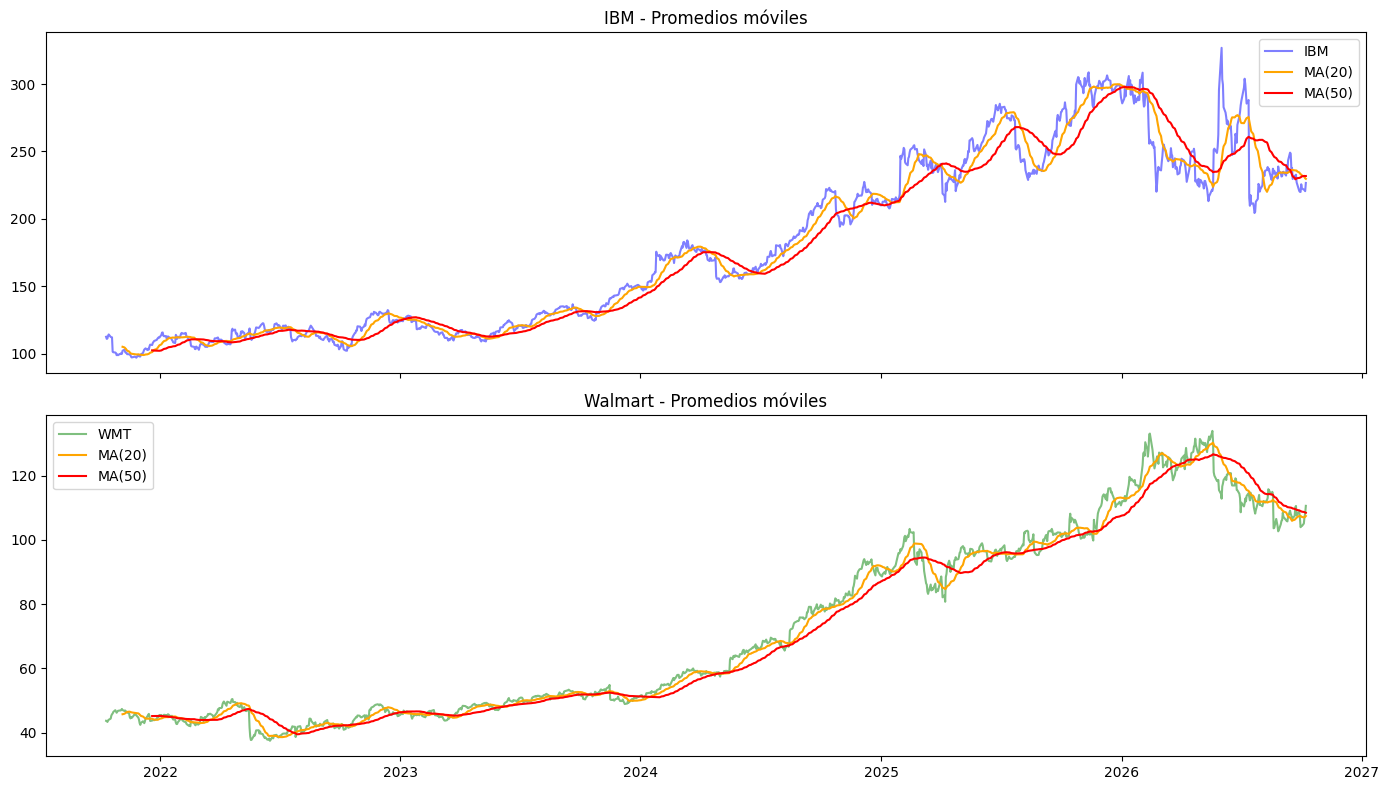

In [31]:
# Promedios móviles
ibm_ma20 = ibm_serie.rolling(20).mean()
ibm_ma50 = ibm_serie.rolling(50).mean()
wmt_ma20 = wmt_serie.rolling(20).mean()
wmt_ma50 = wmt_serie.rolling(50).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(ibm_serie, label="IBM", alpha=0.5, color="blue")
axes[0].plot(ibm_ma20, label="MA(20)", color="orange")
axes[0].plot(ibm_ma50, label="MA(50)", color="red")
axes[0].set_title("IBM - Promedios móviles")
axes[0].legend()

axes[1].plot(wmt_serie, label="WMT", alpha=0.5, color="green")
axes[1].plot(wmt_ma20, label="MA(20)", color="orange")
axes[1].plot(wmt_ma50, label="MA(50)", color="red")
axes[1].set_title("Walmart - Promedios móviles")
axes[1].legend()

plt.tight_layout()
plt.show()

In [32]:
# Pronóstico con el último valor del MA(20)
pron_ibm = ibm_ma20.iloc[-1]
pron_wmt = wmt_ma20.iloc[-1]

print(f"Último precio IBM:      ${ibm_serie.iloc[-1]:.2f}")
print(f"Pronóstico IBM (MA20):  ${pron_ibm:.2f}")
print(f"Último precio WMT:      ${wmt_serie.iloc[-1]:.2f}")
print(f"Pronóstico WMT (MA20):  ${pron_wmt:.2f}")

# Error esperado (desviación estándar de los retornos)
print(f"\nDesv. est. retornos IBM: {ret_ibm_full.std():.4f} ({ret_ibm_full.std()*100:.2f}%)")
print(f"Desv. est. retornos WMT: {ret_wmt_full.std():.4f} ({ret_wmt_full.std()*100:.2f}%)")

Último precio IBM:      $226.61
Pronóstico IBM (MA20):  $229.65
Último precio WMT:      $110.56
Pronóstico WMT (MA20):  $107.40

Desv. est. retornos IBM: 0.0192 (1.92%)
Desv. est. retornos WMT: 0.0142 (1.42%)
